# Hotel Booking Data case study – EDA: do prices rise as check-in approaches?

**Question:** urgency messages like *"book now, prices are rising"* assume prices go up close to check-in. Does the booking data support that?

**Outline:** 0–1 setup & load → 2 data check → 3 EDA (ADR, lead time, length of stay, weekend, seasonality) → 4 core analysis (same-property price curve) → 5 key takeaways

### 0. Setup - import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

### 1. Load - data & merged dataframe
- The Excel file has one sheet per city. Sheets are merged into one dataframe and the misspelled column names are fixed.
- 3 bookings with check-in before the booking date (lead time = -1) are removed and kept in `invalid`.
- New columns: `lead_time`, `length_of_stay`, `lt_band`, check-in / booking month, weekend flags, and `rel_adr` (see 1.2).
- `checkin_weekend` = Friday or Saturday night; `booking_weekend` = booked on Saturday or Sunday.

In [2]:
data = "Case_Study_Urgency_Message_Data.xlsx"

sheets = pd.read_excel(data, sheet_name=None)  # dictionary: {sheet name: dataframe}
column_fixes = {
    "accommadation_type_name": "accommodation_type_name",
    "accommadotion_type_name": "accommodation_type_name",
}
# merge all sheets, sheet name = city
df = pd.concat(
    [sheet.rename(columns=column_fixes).assign(city_name=key) for key, sheet in sheets.items()],
    ignore_index=True)

new_df = df.copy()

# lead time & invalid rows
new_df["lead_time"] = (new_df["checkin_date"] - new_df["booking_date"]).dt.days
invalid = new_df[new_df["lead_time"] < 0].copy()
new_df = new_df[new_df["lead_time"] >= 0].copy()

new_df["length_of_stay"] = (new_df["checkout_date"] - new_df["checkin_date"]).dt.days

new_df["lt_band"] = pd.cut(new_df["lead_time"], bins=[-1, 0, 3, 7, 14, 30, 60],
                           labels=["same day", "1-3", "4-7", "8-14", "15-30", "31-60"])

new_df["checkin_month"] = new_df["checkin_date"].dt.to_period("M").dt.to_timestamp()
new_df["booking_month"] = new_df["booking_date"].dt.to_period("M").dt.to_timestamp()

new_df["checkin_weekend"] = new_df["checkin_date"].dt.dayofweek.isin([4, 5]).map({True: "weekend", False: "weekday"})
new_df["booking_weekend"] = new_df["booking_date"].dt.dayofweek.isin([5, 6]).map({True: "weekend", False: "weekday"})

# relative ADR: each booking vs the median of the same hotel, check-in month and weekday/weekend night
baseline = ["hotel_id", "checkin_month", "checkin_weekend"]
new_df["baseline_size"] = new_df.groupby(baseline)["ADR_USD"].transform("count")
new_df["rel_adr"] = new_df["ADR_USD"] / new_df.groupby(baseline)["ADR_USD"].transform("median")
new_df["rel_adr"] = new_df["rel_adr"].round(3)

print(df.shape)
print(new_df.shape)
new_df.head()

(49064, 11)
(49061, 20)


,#,ADR_USD,hotel_id,city_id,star_rating,accommodation_type_name,chain_hotel,booking_date,checkin_date,checkout_date,city_name,lead_time,length_of_stay,lt_band,checkin_month,booking_month,checkin_weekend,booking_weekend,baseline_size,rel_adr
0,1,71.06,297388,9395,2.5,Hotel,non-chain,2016-08-02,2016-10-01,2016-10-02,City_A,60,1,31-60,2016-10-01,2016-08-01,weekend,weekday,104,1.062
1,2,76.56,298322,9395,3.0,Hotel,non-chain,2016-08-02,2016-10-01,2016-10-02,City_A,60,1,31-60,2016-10-01,2016-08-01,weekend,weekday,16,0.830
2,3,153.88,2313076,9395,5.0,Hotel,chain,2016-08-02,2016-10-01,2016-10-02,City_A,60,1,31-60,2016-10-01,2016-08-01,weekend,weekday,79,0.783
3,4,126.60,2240838,9395,3.5,Hotel,non-chain,2016-08-04,2016-10-02,2016-10-03,City_A,59,1,31-60,2016-10-01,2016-08-01,weekday,weekday,13,1.095
4,5,115.08,2240838,9395,3.5,Hotel,non-chain,2016-08-04,2016-10-02,2016-10-03,City_A,59,1,31-60,2016-10-01,2016-08-01,weekday,weekday,13,0.995


### 1.1. Extract - cleaned data

In [3]:
# Export the cleaned data for a BI tool (run after all cleaning steps).
# new_df.to_csv("cleaned_agoda_2026.csv", index=False)

### 1.2. Helper - price curve function
Raw ADR comparisons mix different properties: a cheap hostel booked last-minute vs a resort booked weeks ahead. To see whether *the same property* changes its price, each booking is compared with its own baseline:

**relative ADR = booking's ADR / median ADR of the same hotel, same check-in month, same weekday/weekend night**

- 1.0 = the property's usual price; above 1.0 = pricier than usual; below 1.0 = cheaper than usual.
- Baseline groups with fewer than 5 bookings are dropped (a median of 1–4 bookings isn't stable).
- Points with fewer than 30 bookings are hidden from the chart.

In [4]:
def price_curve(df, segment, baseline=("hotel_id", "checkin_month", "checkin_weekend"), min_size=5):
    baseline = list(baseline)
    grp_size = df.groupby(baseline)["ADR_USD"].transform("count")
    d = df[grp_size >= min_size].copy()
    d["rel_adr"] = d["ADR_USD"] / d.groupby(baseline)["ADR_USD"].transform("median")

    curve = d.groupby([segment, "lt_band"], observed=True)["rel_adr"].agg(["count", "median"]).round(2)
    curve = curve[curve["count"] >= 30]
    print(f"Bookings kept: {len(d):,} of {len(df):,} ({len(d) / len(df):.0%})")
    print(f"Points shown (count >= 30): {len(curve)}")

    wide = curve["median"].unstack(segment).iloc[::-1]   # far ahead → check-in day
    wide.plot(marker="o", figsize=(10, 5), title=f"Relative ADR by lead time, by {segment}")
    plt.ylim(0.90, 1.10)
    plt.axhline(1, color="gray", linestyle="--")   # 1.0 = property's usual price
    plt.ylabel("Relative ADR")
    plt.xlabel("Days before check-in")
    plt.legend(title=segment, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.show()
    return curve

---

### 2. EDA - Part 1: Data check & clean-up

In [5]:
# column data types & missing values
print(new_df.dtypes)
print("missing values:\n", new_df.isnull().sum())

# duplicates - "#" is a row number, so leave it out
print("dups:", new_df.drop(columns="#").duplicated().sum())

# logic checks on the raw data (before invalid rows were removed)
print("check-ins before booking date:", (df["checkin_date"] < df["booking_date"]).sum())
print("check-outs before check-in:", (df["checkout_date"] < df["checkin_date"]).sum())
print("check-outs before booking date:", (df["checkout_date"] < df["booking_date"]).sum())
print("negative ADR:", (df["ADR_USD"] < 0).sum())

# statistical summary
print(new_df.describe())
print(new_df.nunique())

#                                   int64
ADR_USD                           float64
hotel_id                            int64
city_id                             int64
star_rating                       float64
accommodation_type_name               str
chain_hotel                           str
booking_date               datetime64[us]
checkin_date               datetime64[us]
checkout_date              datetime64[us]
city_name                             str
lead_time                           int64
length_of_stay                      int64
lt_band                          category
checkin_month              datetime64[us]
booking_month              datetime64[us]
checkin_weekend                       str
booking_weekend                       str
baseline_size                       int64
rel_adr                           float64
dtype: object
missing values:
 #                          0
ADR_USD                    0
hotel_id                   0
city_id                    0
star_rating  

#### Data quality and coverage summary
- 0 missing values; 1,024 duplicate rows (2%) once the row number `#` is ignored: same hotel, dates and ADR. Without a booking ID these can't be told apart from real separate bookings (e.g. two rooms booked together), so they're kept.
- Removed 3 bookings with check-in before the booking date (<0.01% of the dataset). They're shown below.
- No check-outs before check-in and no negative ADR.
- Booking dates: Aug 2 – Dec 31, 2016. Check-in dates: Oct 1 – Dec 31, 2016. 880 hotels in 5 cities.
- Lead time is capped at 60 days and stays are 1–3 nights only.

#### Invalid rows - check-in one day before the booking date (lead time = -1)

In [6]:
invalid

,#,ADR_USD,hotel_id,city_id,star_rating,accommodation_type_name,chain_hotel,booking_date,checkin_date,checkout_date,city_name,lead_time
13263,13264,148.98,461164,9395,4.0,Hotel,chain,2016-11-13,2016-11-12,2016-11-13,City_A,-1
45546,1300,74.30,1667520,8584,3.0,Hotel,non-chain,2016-10-15,2016-10-14,2016-10-15,City_E,-1
46252,2006,28.52,3198626,8584,0.0,Guest House / Bed & Breakfast,non-chain,2016-10-30,2016-10-29,2016-10-30,City_E,-1


---

### 3. EDA - Part 2: ADR distribution

#### ADR_USD distribution - manual check

In [7]:
# ADR distribution
adr = new_df['ADR_USD']
#print(adr.describe())
print(adr.agg(["mean", "median", "std", "min", "max", "skew", "kurt"]).round(2))

mean       148.09
median     113.66
std        135.34
min          4.26
max       3156.86
skew         4.53
kurt        45.07
Name: ADR_USD, dtype: float64


In [8]:
# percentiles
adr.describe(percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]).round(2)

count    49061.00
mean       148.09
std        135.34
min          4.26
1%          20.00
5%          36.42
10%         42.90
25%         62.56
50%        113.66
75%        192.22
90%        285.32
95%        366.44
99%        638.15
max       3156.86
Name: ADR_USD, dtype: float64

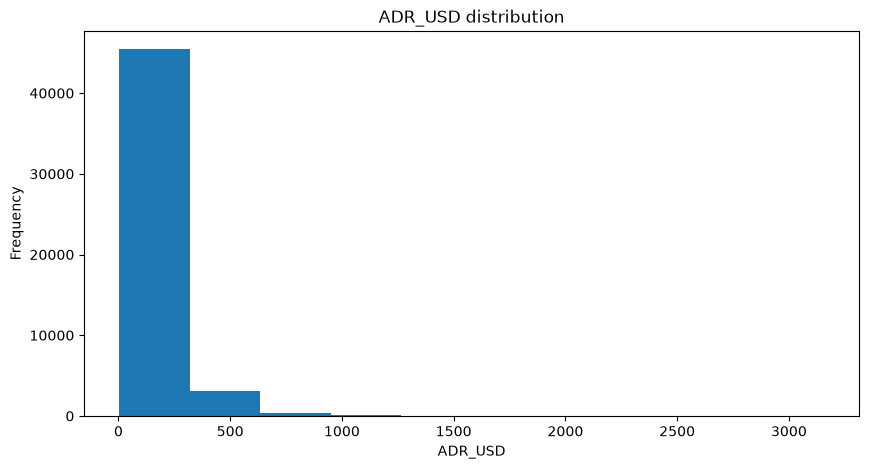

In [9]:
adr.plot.hist(bins=10, title="ADR_USD distribution", figsize=(10, 5)).set_xlabel("ADR_USD")
plt.show()

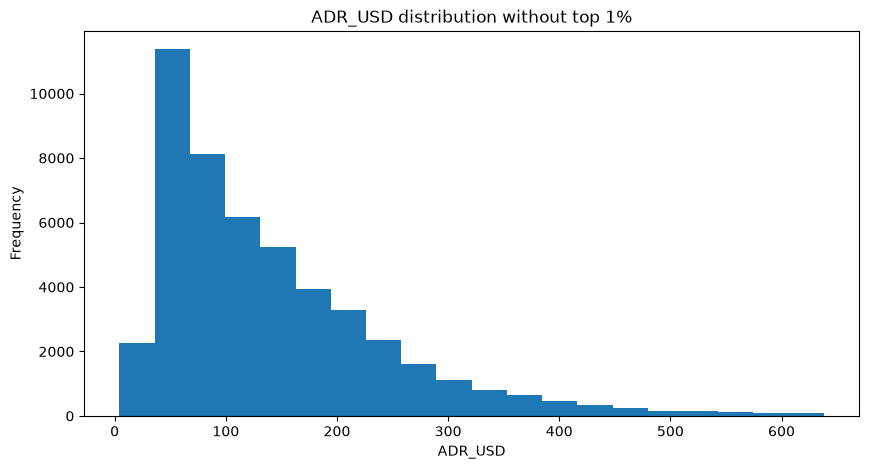

In [10]:
# histogram without the top 1% tail
without_tail = new_df[new_df["ADR_USD"] <= new_df["ADR_USD"].quantile(0.99)]
without_tail["ADR_USD"].plot.hist(bins=20, title="ADR_USD distribution without top 1%", figsize=(10, 5)).set_xlabel("ADR_USD")
plt.show()

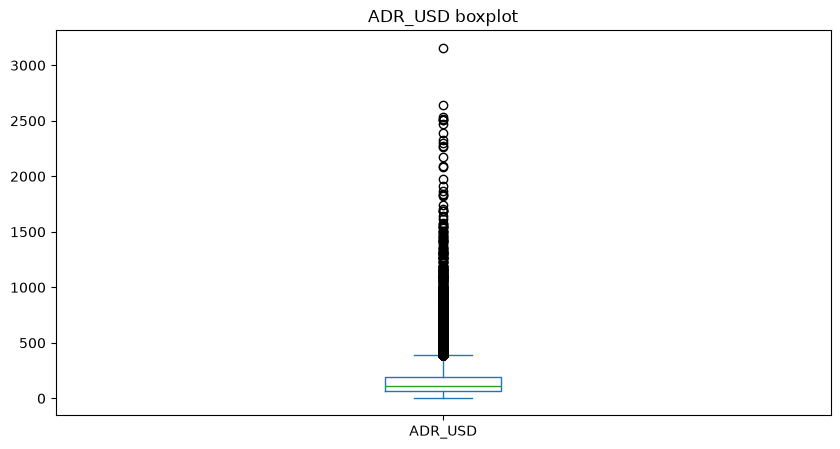

In [11]:
adr.plot.box(title="ADR_USD boxplot", figsize=(10, 5))
plt.show()

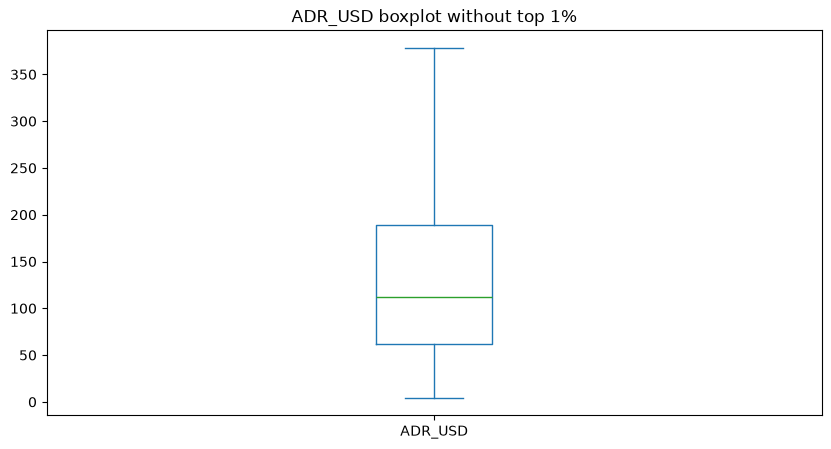

In [12]:
# boxplot without outliers shown
without_tail["ADR_USD"].plot.box(title="ADR_USD boxplot without top 1%", figsize=(10, 5), showfliers=False)
plt.show()

#### Summary of ADR_USD
- Typical ADR is $63–$192 (middle 50%).
- Mean $148 vs median $114: half of the bookings are under $114, but the mean is ~30% higher because a small number of expensive bookings pull it up. Median is the better measure of a typical ADR.
- Std $135: almost as big as the mean, so ADR is very spread out. With skewed data the long right tail inflates the std, so it isn't very meaningful here.
- Min $4 vs max $3,157: both ends look suspicious. $4 could be a data issue (currency conversion, per-person rate, partial booking); $3,157 could be a luxury suite or also a data issue. Flagged but kept.
- Skew 4.5: anything above 1 is highly skewed, so this confirms a long right tail.

#### City profile - manual check

In [13]:
# ADR distribution by city
print(new_df.groupby('city_name')['ADR_USD'].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).round(2))

           count    mean  median     std    min      max  skew   kurt
city_name                                                            
City_A     22365  100.51   83.50   66.54   4.26  1099.69  2.30  11.47
City_B      4932  118.32   79.73  134.12   6.92  2326.24  5.48  46.85
City_C      6797  224.84  190.49  199.07  20.79  3156.86  4.34  37.35
City_D     10152  218.85  192.90  141.87  14.18  2303.18  3.60  26.25
City_E      4815  142.11   94.76  137.69  12.66  1709.24  3.78  24.57


In [14]:
new_df.groupby('city_name')['ADR_USD'].describe(percentiles=[.25, .50, .75]).round(2)

,count,mean,std,min,25%,50%,75%,max
city_name,,,,,,,,
City_A,22365.0,100.51,66.54,4.26,52.20,83.50,128.14,1099.69
City_B,4932.0,118.32,134.12,6.92,54.69,79.73,139.51,2326.24
City_C,6797.0,224.84,199.07,20.79,91.74,190.49,282.33,3156.86
City_D,10152.0,218.85,141.87,14.18,139.02,192.90,266.21,2303.18
City_E,4815.0,142.11,137.69,12.66,57.63,94.76,205.29,1709.24


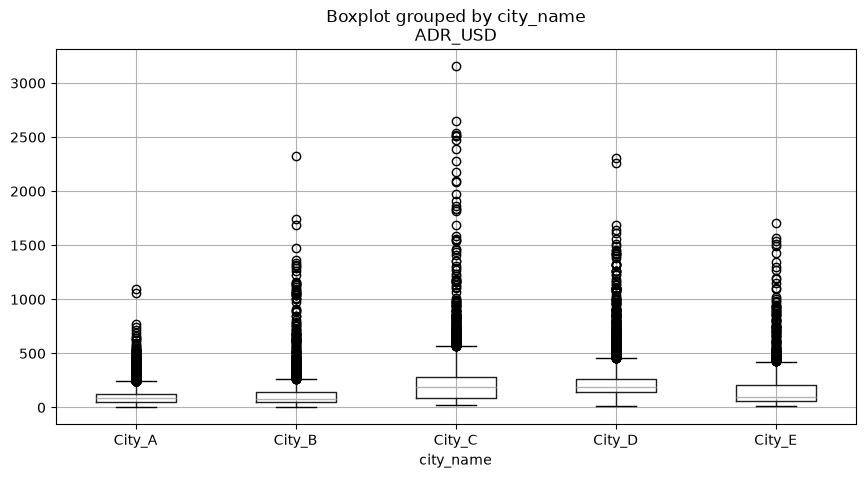

In [15]:
new_df.boxplot(column="ADR_USD", by="city_name", figsize=(10, 5), showfliers=True)
plt.show()

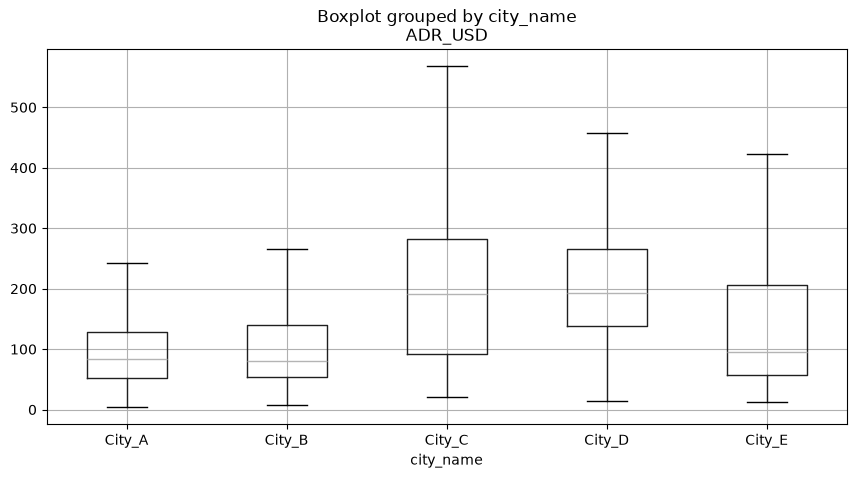

In [16]:
new_df.boxplot(column="ADR_USD", by="city_name", figsize=(10, 5), showfliers=False)
plt.show()

#### Summary of ADR distribution by city
- Two price tiers: City C and D are the high-priced markets (median ~$190), while City A, B and E are lower-priced (median ~$80–95).
- All cities are right-skewed (mean > median, skew > 1), so median is the better measure when comparing markets.
- City A makes up ~46% of bookings, so it heavily drives the overall numbers. It's also the most consistent market: lowest skew, max around $1,100.
- City C has the widest price range in dollars, both in its typical bookings (middle 50% ~$90–280) and its extremes (up to $3,156).
- City E has the most mixed typical prices relative to its median: its middle 50% stretches from ~$58 to ~$205.
- City B looks like a budget market but has the most extreme tail: std is 1.7x its median (0.7–1.5x elsewhere), outliers reach ~$2,300 against a median of ~$80, and it has the highest skew and kurtosis.
- Many bookings fall above the boxplot whiskers in every city. Most are likely real high-end stays, but extreme values (e.g. $4.26 in City A, $3,156 in City C) should be checked for data quality.

### 3.1. Data distribution function - repeated check
Runs the same summary stats, histogram (without the top 1%) and boxplots by city, accommodation type, star rating and chain status for any measure.

In [17]:
def data_distribution(measure):
    print(measure)
    print(new_df[measure].agg(["mean", "median", "std", "min", "max", "skew", "kurt"]).round(2))

    # histogram without the top 1% tail
    without_tail = new_df[new_df[measure] <= new_df[measure].quantile(0.99)]
    without_tail[measure].plot.hist(bins=20, title=f"{measure} distribution without top 1%", figsize=(10, 5)).set_xlabel(measure)

    categorical_cols = ["city_name", "accommodation_type_name", "star_rating", "chain_hotel"]
    for col in categorical_cols:
        print(new_df.groupby(col)[measure].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).round(2))
        new_df.boxplot(column=measure, by=col, figsize=(15, 5), showfliers=False)

#### ADR_USD by segment

ADR_USD
mean       148.09
median     113.66
std        135.34
min          4.26
max       3156.86
skew         4.53
kurt        45.07
Name: ADR_USD, dtype: float64
           count    mean  median     std    min      max  skew   kurt
city_name                                                            
City_A     22365  100.51   83.50   66.54   4.26  1099.69  2.30  11.47
City_B      4932  118.32   79.73  134.12   6.92  2326.24  5.48  46.85
City_C      6797  224.84  190.49  199.07  20.79  3156.86  4.34  37.35
City_D     10152  218.85  192.90  141.87  14.18  2303.18  3.60  26.25
City_E      4815  142.11   94.76  137.69  12.66  1709.24  3.78  24.57
                               count    mean  median  ...      max  skew   kurt
accommodation_type_name                               ...                      
Apartment                        239  196.31  183.20  ...   623.95  0.76   0.18
Bungalow                         142   71.87   73.97  ...   189.76  0.51   2.10
Capsule Hotel             

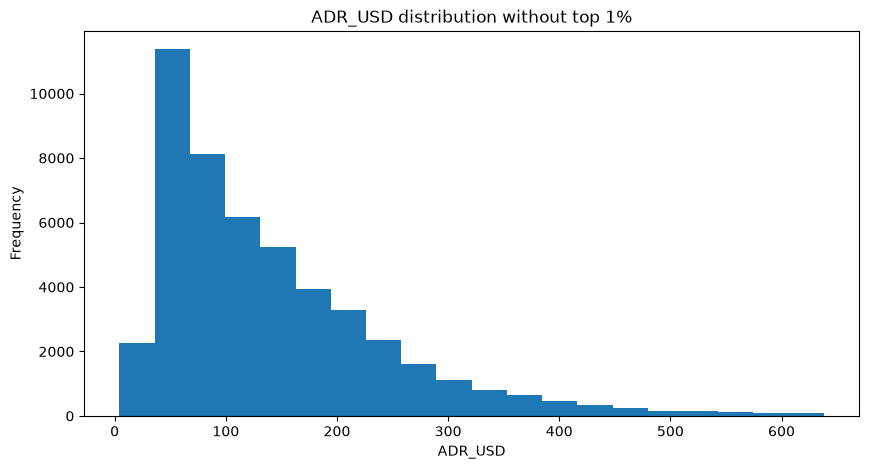

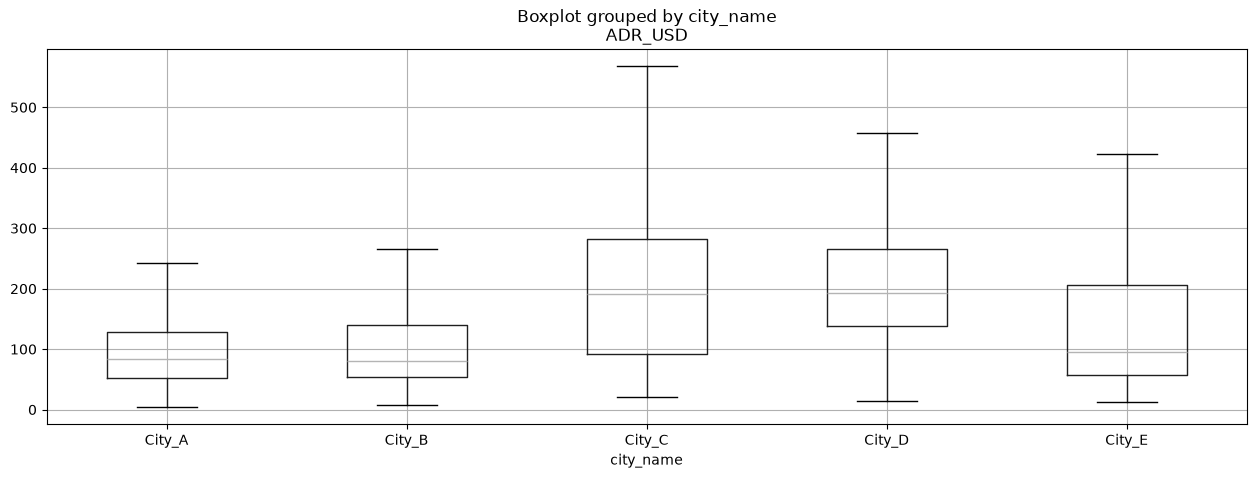

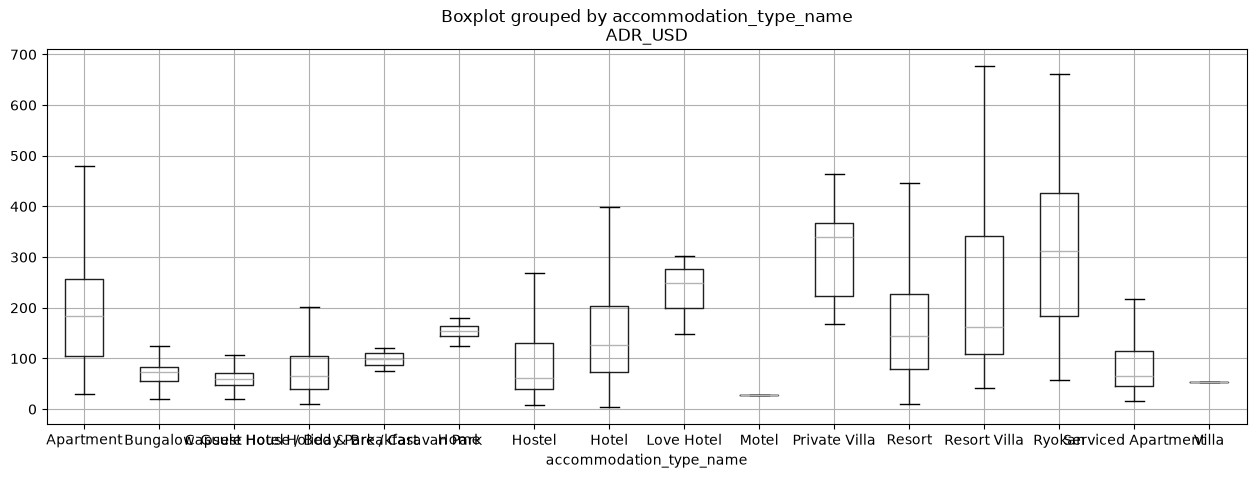

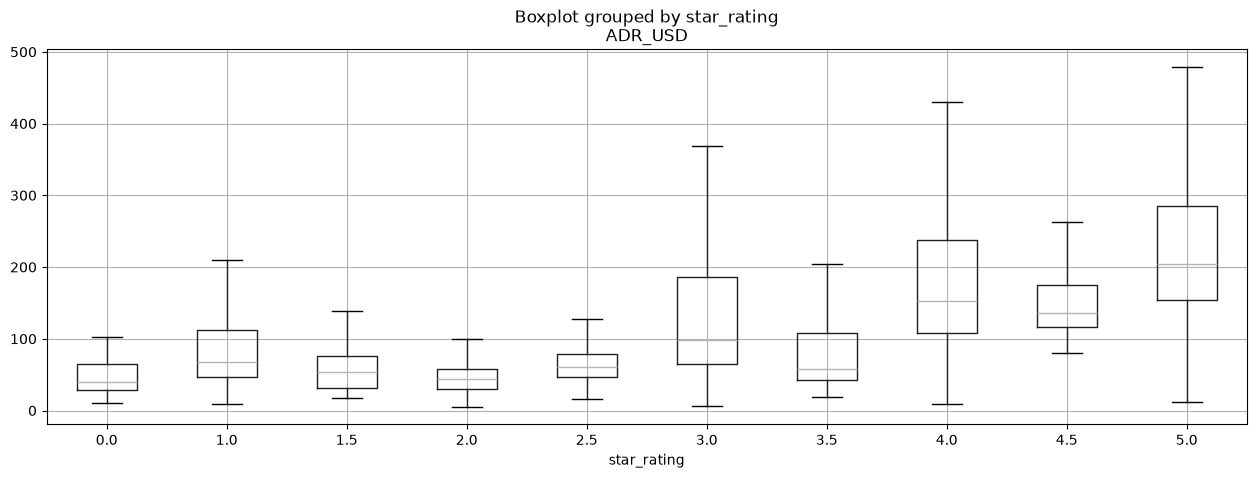

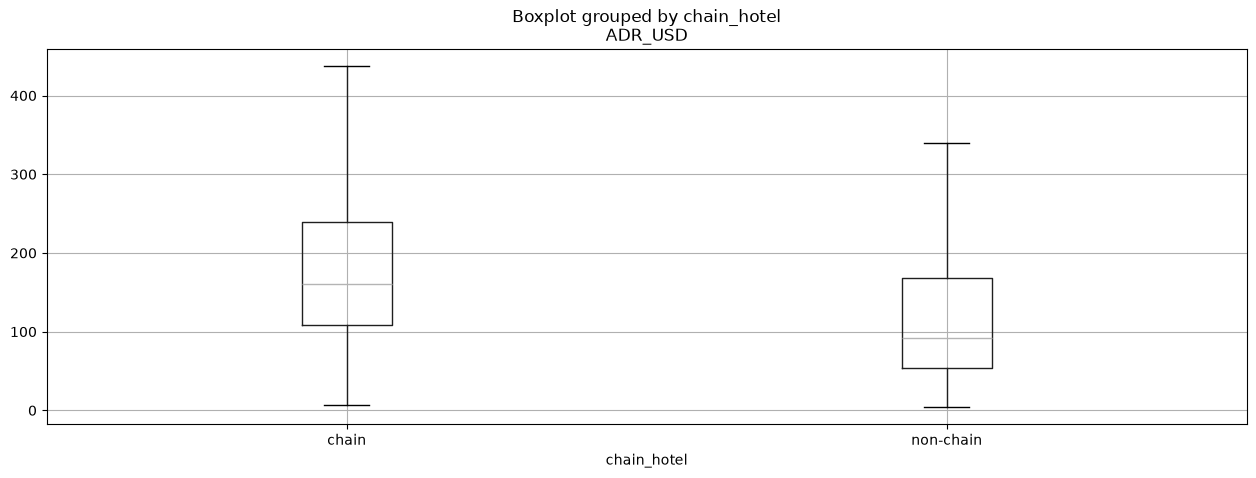

In [18]:
data_distribution("ADR_USD")

#### Summary of ADR by accommodation type
1. **Hotels dominate the data.** Hotel is 35,439 of ~49,000 bookings (about 72%), so overall ADR is mostly a hotel story. Both suspicious extremes ($4.26 and $3,156) are also hotels.

2. **Several types are too small to trust.** Villa (1), Holiday Park (3), Love Hotel (3), Home (14), Private Villa (18) and Motel (27) are too small for their stats to mean much. Love Hotel's $249 median is just 3 bookings. These are grouped into "Other" below (minimum 30 bookings).

3. **There's a clear price ladder by median** (types with 30+ bookings):
   - Premium: Ryokan ($313), Apartment ($183), Resort Villa ($163), Resort ($144)
   - Mid: Hotel ($126)
   - Budget: Bungalow ($74), Serviced Apartment ($66), Guest House ($65), Hostel ($62), Capsule Hotel ($59)

4. **Some types are priced consistently, others aren't.**
   - Ryokan and Apartment are expensive but predictable: low skew (0.31 and 0.76), mean close to median.
   - Resort Villa and Resort have big tails. Resort Villa's mean ($259) is about 60% above its median ($163), so a few luxury stays pull it up.
   - Hotel has the most extreme tail (skew 4.7, kurtosis 51.5), which makes sense since it covers everything from budget to luxury.

5. **Budget types have surprisingly high maxes.** A $601 hostel, a $914 guest house and a $547 serviced apartment look odd. These could be private rooms, group bookings, or ADR calculated per booking instead of per room. Worth checking.

6. **Motel prices are extremely uniform.** The std is only $4.50 around a $28 median, explained by there being only two Motel properties (checked below).

7. **Similar labels are kept separate.** Villa / Private Villa / Resort Villa and Apartment / Serviced Apartment sound similar, but their prices differ significantly (Mann-Whitney U test below), and merging would hide the smaller, pricier group because the larger group is 92–95% of the merged count.

#### Mann-Whitney check - are similar labels really different?

In [19]:
def compare(a, b, measure):
    x = new_df.loc[new_df["accommodation_type_name"] == a, measure]
    y = new_df.loc[new_df["accommodation_type_name"] == b, measure]
    stat, p = mannwhitneyu(x, y)
    print(f"{measure} | {a} vs {b}: medians {x.median():.1f} vs {y.median():.1f}, p = {p:.4f}")

for m in ["ADR_USD", "lead_time"]:
    compare("Apartment", "Serviced Apartment", m)
    compare("Private Villa", "Resort Villa", m)

ADR_USD | Apartment vs Serviced Apartment: medians 183.2 vs 65.8, p = 0.0000
ADR_USD | Private Villa vs Resort Villa: medians 339.2 vs 163.0, p = 0.0018
lead_time | Apartment vs Serviced Apartment: medians 12.0 vs 5.0, p = 0.0000
lead_time | Private Villa vs Resort Villa: medians 9.0 vs 13.0, p = 0.5664


- ADR: both pairs differ significantly (Apartment vs Serviced Apartment p < 0.0001; Private Villa vs Resort Villa p = 0.002), so the labels are kept separate.
- Lead time: Apartment vs Serviced Apartment also differ (12 vs 5 days, p < 0.0001). Private Villa vs Resort Villa don't (p = 0.57), but Private Villa has only 18 bookings.

#### Motel - how many properties?

In [20]:
new_df.loc[new_df["accommodation_type_name"] == "Motel", "hotel_id"].unique()

array([1820604, 2826416])

#### Accommodation type by city
- Capsule Hotel, Love Hotel and Ryokan look like Japanese property types. Are they concentrated in one city?
- The crosstab shows they are almost all in City C, so City C is likely a Japanese city.
- So city and accommodation type are partly tangled together: a difference between types can partly be a city effect.

In [21]:
pd.crosstab(new_df["accommodation_type_name"], new_df["city_name"])

city_name,City_A,City_B,City_C,City_D,City_E
accommodation_type_name,,,,,
Apartment,51,34,137,0,17
Bungalow,0,141,0,0,1
Capsule Hotel,0,0,822,0,0
Guest House / Bed & Breakfast,520,532,374,991,340
Holiday Park / Caravan Park,0,3,0,0,0
Home,0,0,1,12,1
Hostel,1002,17,408,1269,78
Hotel,18397,1890,4830,7783,2539
Love Hotel,0,0,3,0,0


In [22]:
stats = new_df.groupby("accommodation_type_name")["ADR_USD"].agg(["count", "median", "mean", "skew"]).round(2)
print(stats[stats["count"] >= 30].sort_values("median", ascending=False))
print(stats.sort_values("median", ascending=False))

                               count  median    mean  skew
accommodation_type_name                                   
Ryokan                           103  312.96  314.77  0.31
Apartment                        239  183.20  196.31  0.76
Resort Villa                     397  162.98  259.49  2.65
Resort                          3525  143.80  190.98  3.44
Hotel                          35439  126.25  158.13  4.72
Bungalow                         142   73.97   71.87  0.51
Serviced Apartment              2797   65.82   90.07  2.44
Guest House / Bed & Breakfast   2757   64.54   85.78  3.58
Hostel                          2774   62.38   88.78  1.83
Capsule Hotel                    822   59.22   61.31  1.47
                               count  median    mean  skew
accommodation_type_name                                   
Private Villa                     18  339.16  338.96  2.57
Ryokan                           103  312.96  314.77  0.31
Love Hotel                         3  249.10  233.44 -0.

#### Clean up accommodation type
- Types with fewer than 30 bookings (~0.06% of all bookings) are treated as noise and grouped as "Other" in `acco_type_name_clean`.

In [23]:
type_counts = new_df["accommodation_type_name"].value_counts()
new_df["acco_type_name_clean"] = new_df["accommodation_type_name"].apply(lambda x: x if type_counts[x] >= 30 else "Other")
new_df["acco_type_name_clean"].value_counts()

acco_type_name_clean
Hotel                            35439
Resort                            3525
Serviced Apartment                2797
Hostel                            2774
Guest House / Bed & Breakfast     2757
Capsule Hotel                      822
Resort Villa                       397
Apartment                          239
Bungalow                           142
Ryokan                             103
Other                               66
Name: count, dtype: int64

#### ADR by chain status and accommodation type

In [24]:
(new_df.groupby(["chain_hotel", "accommodation_type_name"])["ADR_USD"]
       .agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).round(2)
       .sort_values(["chain_hotel", "count"], ascending=False))

count    mean  ...  skew   kurt
chain_hotel accommodation_type_name                       ...             
non-chain   Hotel                          23592  136.44  ...  2.05   6.53
            Guest House / Bed & Breakfast   2757   85.78  ...  3.58  24.41
            Hostel                          2702   89.94  ...  1.80   4.81
            Serviced Apartment              2669   83.02  ...  2.28   8.10
            Resort                          2506  193.64  ...  2.91  11.13
            Capsule Hotel                    822   61.31  ...  1.47   3.44
            Resort Villa                     353  272.05  ...  2.53   7.96
            Apartment                        142  140.25  ...  1.07   1.78
            Bungalow                         142   71.87  ...  0.51   2.10
            Ryokan                            75  322.26  ...  0.58   0.33
            Motel                             27   28.07  ...  3.08  14.41
            Private Villa                     18  338.96  ...  2.57   8.76
            Home                              13  161.15  ...  2.36   7.13
            Holiday Park / Caravan Park        3   98.19  ... -0.12    NaN
            Love Hotel                         3  233.44  ... -0.87    NaN
            Villa                              1   54.29  ...   NaN    NaN
chain       Hotel                          11847  201.34  ...  5.42  51.08
            Resort                          1019  184.45  ...  5.13  42.34
            Serviced Apartment               128  237.03  ...  0.19  -0.86
            Apartment                         97  278.38  ...  0.45  -0.35
            Hostel                            72   45.46  ...  0.37  -0.27
            Resort Villa                      44  158.77  ...  2.48   6.22
            Ryokan                            28  294.73  ... -0.19  -1.43
            Home                               1  627.66  ...   NaN    NaN

[24 rows x 8 columns]

#### Summary of ADR by chain status
Chain properties are priced higher, but the gap isn't the same everywhere, and part of it comes from what each group sells.

1. **The headline gap is partly a mix effect.** Chain median is $161 vs non-chain $92, about 75% higher. But non-chain includes almost all the budget types (hostels, guest houses, capsule hotels, cheap serviced apartments), which drag its median down. Comparing totals mixes "chain vs non-chain" with "hotel vs hostel".

2. **Like-for-like, there's still a real chain premium for hotels.** Chain hotels have a $162 median vs $106 for non-chain, about 52% higher. Hotel is about 90% of chain bookings, so this is the comparison that matters most.

3. **The premium doesn't hold for every type.**
   - Resort: chain $135 vs non-chain $148, so chain is cheaper.
   - Resort Villa: chain $122 vs non-chain $173 (only 44 chain bookings).
   - Hostel: chain $48 vs non-chain $63 (72 chain bookings).
   - Ryokan: about the same either way ($309–323).

4. **Serviced Apartment and Apartment show the biggest chain effect.** Chain serviced apartments are $234 vs $63 non-chain, almost 4x. Chain apartments are $247 vs $131. So the gap between Apartment and Serviced Apartment isn't only about the label; chain status plays a big part. Within non-chain alone, Apartment ($131) is still about 2x Serviced Apartment ($63), so keeping them separate still makes sense.

5. Chain is about 27% of bookings (13,236 of 49,061); non-chain is about 73%.

### 3. EDA - Part 3: Lead time distribution

lead_time
mean      14.53
median     8.00
std       15.68
min        0.00
max       60.00
skew       1.15
kurt       0.32
Name: lead_time, dtype: float64
           count   mean  median    std  min  max  skew  kurt
city_name                                                   
City_A     22365  13.27     7.0  15.12    0   60  1.29  0.75
City_B      4932  13.88     6.0  16.20    0   60  1.17  0.24
City_C      6797  20.61    16.0  16.97    0   60  0.64 -0.72
City_D     10152  15.13     9.0  15.38    0   60  1.13  0.32
City_E      4815  11.21     5.0  14.07    0   60  1.54  1.56
                               count   mean  median  ...  max  skew  kurt
accommodation_type_name                              ...                 
Apartment                        239  16.41    12.0  ...   58  1.03  0.14
Bungalow                         142  11.33     3.0  ...   60  1.48  1.00
Capsule Hotel                    822  17.41    12.0  ...   60  0.92 -0.16
Guest House / Bed & Breakfast   2757  13.48     7

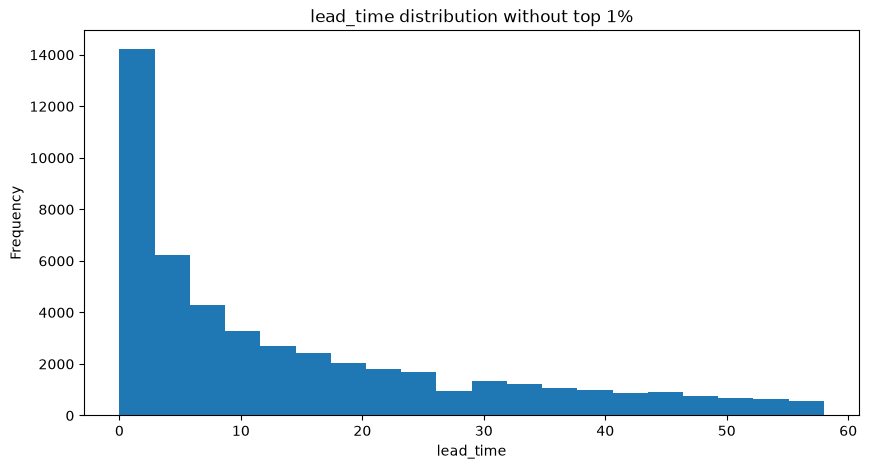

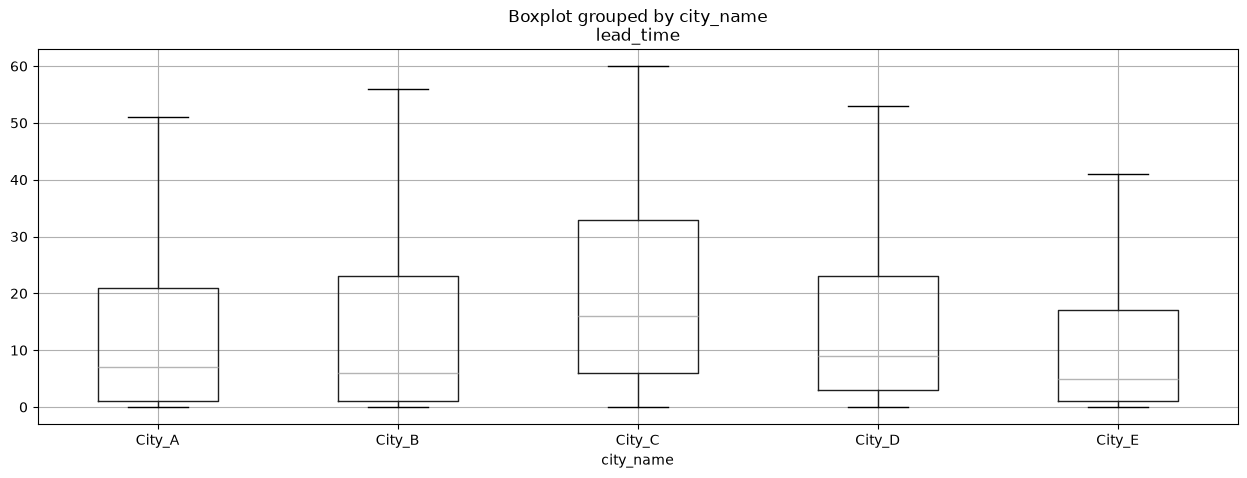

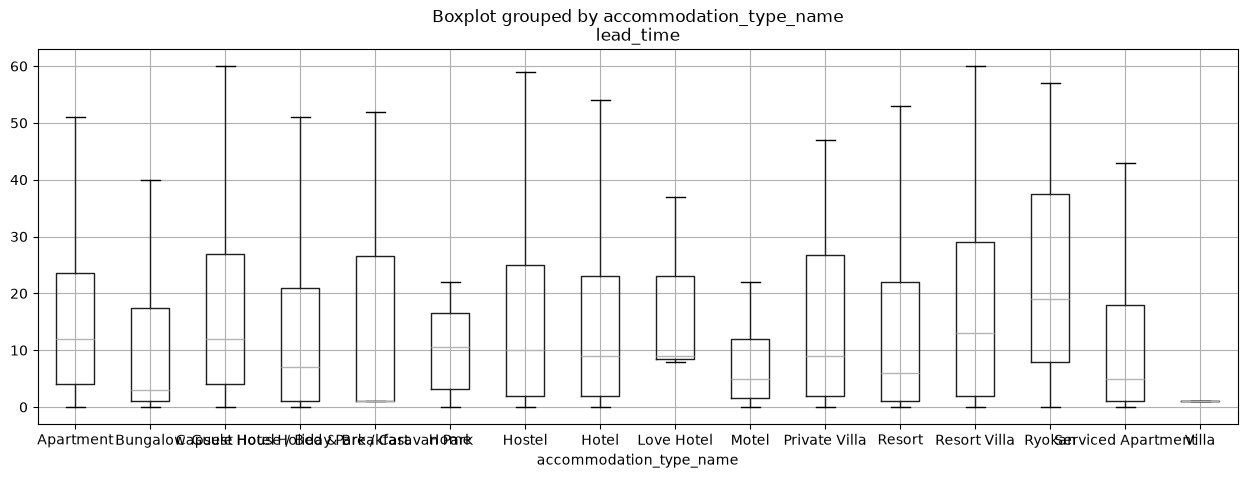

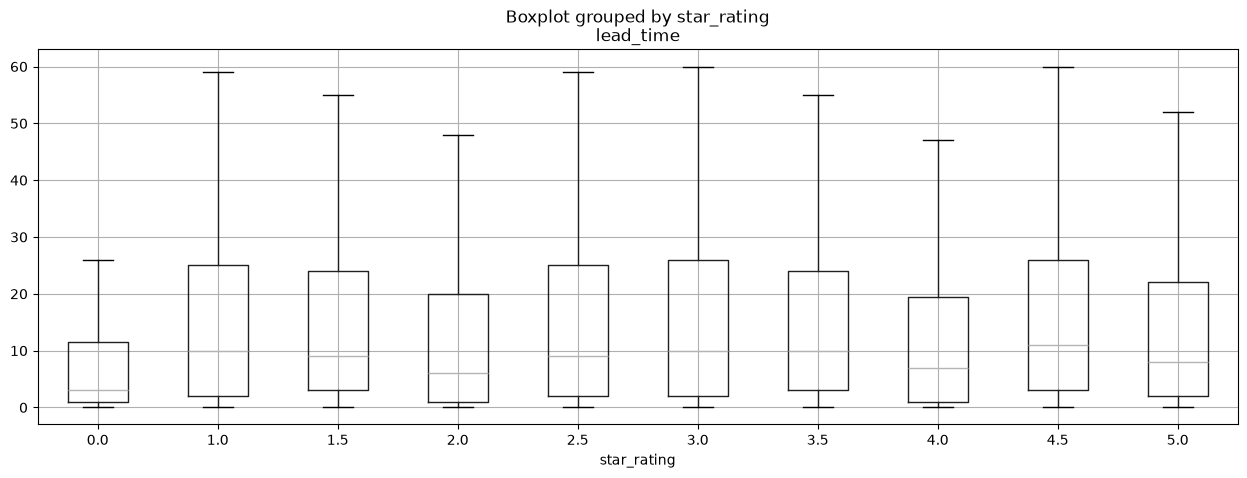

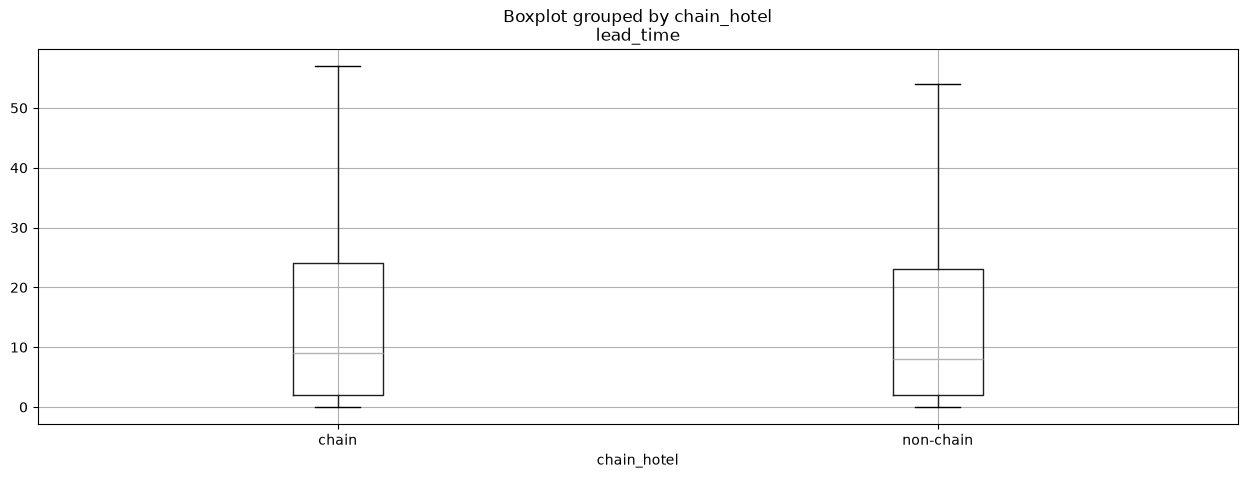

In [25]:
data_distribution("lead_time")  # negative lead times were already removed in section 1

#### Summary of lead time
1. Overall: right-skewed (median 8 vs mean 14.5 days); most bookings are made within ~1 week of check-in. Max is 60 in every group, which suggests a cap in the data, so the tail is cut off.
2. City A is ~46% of bookings and drives the overall numbers.
3. City C stands out: median 16 days, about double the other cities, and more evenly spread (lowest skew). Guests book further ahead there.
4. City E (median 5) and City B (median 6) are the most last-minute markets. City E has the highest skew: mostly last-minute, with a small group of early bookers.
5. By accommodation type, medians range from 3 (Bungalow) to 19 days (Ryokan). Ryokan and Capsule Hotel book furthest ahead, possibly a City C effect. Apartment (12) vs Serviced Apartment (5) also differ, supporting keeping them separate.
6. Star rating and chain status show no meaningful lead time difference.

### 3. EDA - Part 4: Lead time vs ADR
**Hypothesis:** expensive bookings are made further ahead.

In [26]:
# Correlation (Spearman works well for skewed data)
print(new_df[["ADR_USD", "lead_time"]].corr(method="spearman"))

# Median lead time by price band
new_df["adr_band"] = pd.cut(new_df["ADR_USD"], bins=[0, 100, 200, 300, 500, 5000])
print(new_df.groupby("adr_band", observed=True)["lead_time"].agg(["count", "median"]))

            ADR_USD  lead_time
ADR_USD    1.000000   0.161301
lead_time  0.161301   1.000000
             count  median
adr_band                  
(0, 100]     21890     6.0
(100, 200]   15797     9.0
(200, 300]    7081    12.0
(300, 500]    3313    12.0
(500, 5000]    980    15.0


In [27]:
# Does the pattern hold within each city?
new_df.pivot_table(index="adr_band", columns="city_name", values="lead_time",
                   aggfunc=["count", "median"], observed=True)

count                       ... median                     
city_name   City_A City_B City_C City_D  ... City_B City_C City_D City_E
adr_band                                 ...                            
(0, 100]     13320   3069   1784   1179  ...    4.0   10.0    8.0    4.0
(100, 200]    7449   1253   1869   4230  ...   11.0   17.0    9.0    5.0
(200, 300]    1226    358   1632   2941  ...   10.0   20.0   12.0    4.0
(300, 500]     341    156   1070   1487  ...   16.0   21.0    7.0    9.0
(500, 5000]     29     96    442    315  ...   20.0   18.5    7.0   12.0

[5 rows x 10 columns]

#### Summary: ADR vs lead time
- **The price bands show a clear upward trend.** Median lead time climbs from 6 days (under $100) to 9, 12, and 15 days (over $500). Expensive bookings are made further ahead, a 2.5x difference between the cheapest and priciest bands.
- **But the correlation is weak (Spearman 0.16).** Within each band there's huge variation: plenty of $50 bookings made 50 days ahead and $600 bookings made the same day. Price nudges lead time, but most of what drives lead time is something else.
- The two results don't conflict: the *typical* booking in each band shifts steadily, but individual bookings are scattered.

**By city**
- The pattern holds within most cities (A, B, C, and E at the top end), so it isn't explained by destination alone.
- City D is the exception: its priciest bookings have short lead times (median 7 days, 1,800+ bookings above $300).
- City C has the longest lead times in nearly every price band, so destination is linked to lead time independently of price.
- Top price bands are thin in City A (29 bookings above $500) and City B / E (~100), so those medians are rough indications, not firm numbers.

**Why ADR and lead time could be linked without price causing it**
- A third factor drives both: destination (like City C), trip type (holiday vs business or weekend trip) or traveler type could lead to both pricier stays and earlier planning.
- The direction could be reversed: with dynamic pricing, *when* you book affects the price, so lead time could partly drive ADR. Section 4 tests this.
- Different products: resorts, ryokans and apartments may attract travelers who plan ahead for reasons unrelated to price.

### 3. EDA - Part 5: Lead time vs length of stay

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 12


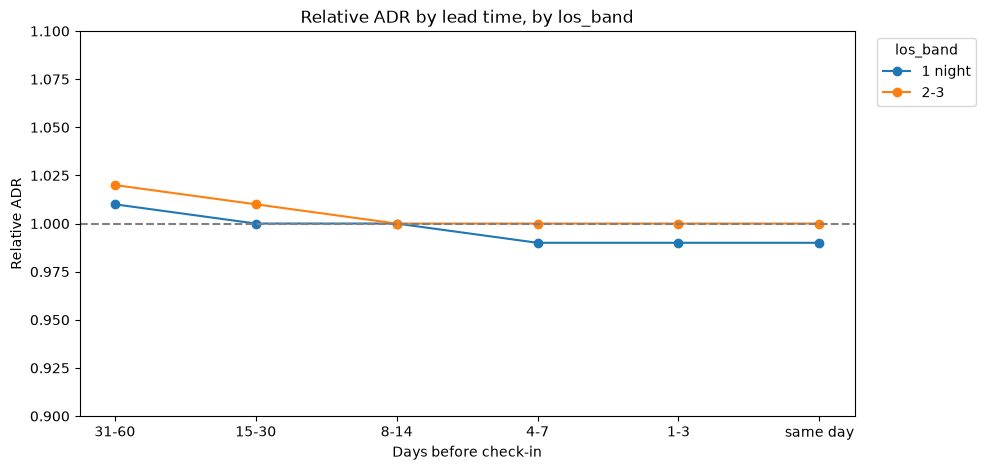

count  median
los_band lt_band                
1 night  same day   3850    0.99
         1-3        5996    0.99
         4-7        3427    0.99
         8-14       3296    1.00
         15-30      3897    1.00
         31-60      3073    1.01
2-3      same day   1245    1.00
         1-3        4223    1.00
         4-7        2999    1.00
         8-14       3518    1.00
         15-30      5309    1.01
         31-60      4864    1.02

In [28]:
new_df["los_band"] = pd.cut(new_df["length_of_stay"], bins=[0, 1, 3, 7, 100],
                            labels=["1 night", "2-3", "4-7", "8+"])
price_curve(new_df, "los_band")

- The dataset only has 1–3 night stays. Both 1-night and 2–3-night stays show the same slight downward drift (1.01–1.02 far ahead → 0.99–1.00 same day), so length of stay doesn't change the pattern.
- Results may not apply to longer stays.

### 3. EDA - Part 6: Check-in on a weekend or weekday

In [29]:
new_df.groupby('checkin_weekend')['ADR_USD'].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).round(2)

,count,mean,median,std,min,max,skew,kurt
checkin_weekend,,,,,,,,
weekday,30426,139.49,110.18,121.93,4.64,2388.40,4.15,36.53
weekend,18635,162.14,118.96,153.73,4.26,3156.86,4.65,46.48


- Weekday covers 5 nights (Sunday–Thursday) and weekend covers 2 (Friday–Saturday). Per night of the week:
  - Weekday: 30,426 / 5 ≈ 6,100 bookings per night
  - Weekend: 18,635 / 2 ≈ 9,300 bookings per night
- So each weekend night gets about 50% more bookings than a weekday night. Weekday's total is bigger only because it covers more days.
- Weekend nights are priced higher: median ADR $119 vs $110 (about 8%). The mean gap is bigger ($162 vs $139) because weekend has a heavier expensive tail (higher skew and kurtosis, and the $3,156 max).

#### Price curve with a baseline that mixes weekday and weekend nights (hotel + check-in month only)

Bookings kept: 47,340 of 49,061 (96%)
Points shown (count >= 30): 12


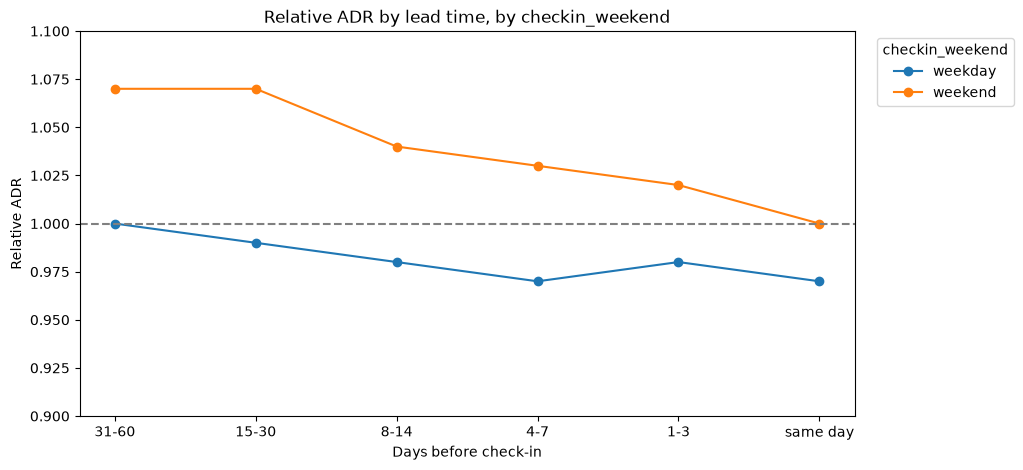

count  median
checkin_weekend lt_band                
weekday         same day   3493    0.97
                1-3        6697    0.98
                4-7        4349    0.97
                8-14       4331    0.98
                15-30      5672    0.99
                31-60      4894    1.00
weekend         same day   1849    1.00
                1-3        3923    1.02
                4-7        2255    1.03
                8-14       2704    1.04
                15-30      3837    1.07
                31-60      3336    1.07

In [30]:
price_curve(new_df, "checkin_weekend", baseline=["hotel_id", "checkin_month"])

- With this baseline, weekend stays look about 7% pricier when booked far ahead (1.07 → 1.00), and weekday stays drift about 3% (1.00 → 0.97).
- But this isn't comparing like with like: each booking is compared with a hotel median that mixes cheaper weekday nights and pricier weekend nights. Rerun with weekday/weekend in the baseline:

#### Price curve with weekday/weekend in the baseline (hotel + check-in month + weekday/weekend)

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 12


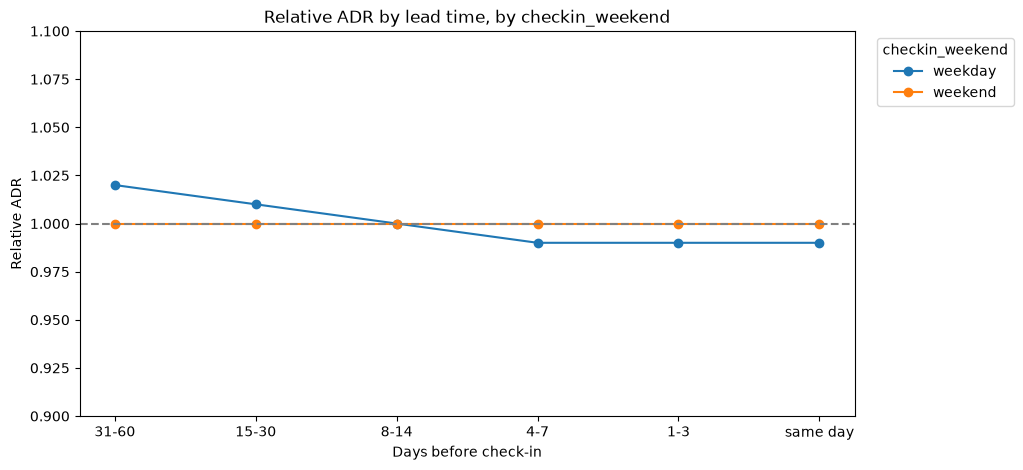

count  median
checkin_weekend lt_band                
weekday         same day   3372    0.99
                1-3        6526    0.99
                4-7        4280    0.99
                8-14       4248    1.00
                15-30      5545    1.01
                31-60      4775    1.02
weekend         same day   1723    1.00
                1-3        3693    1.00
                4-7        2146    1.00
                8-14       2566    1.00
                15-30      3661    1.00
                31-60      3162    1.00

In [31]:
price_curve(new_df, "checkin_weekend")

- Comparing weekend nights only with weekend nights at the same hotel and month, the weekend line is flat (1.00 in every band). Weekday drifts about 3% (1.02 → 0.99).
- So the 7% weekend slope was an artifact of the baseline. That's why `checkin_weekend` is part of the default baseline in `price_curve`.

#### Sanity check - is the flat weekend line just many bookings sitting exactly at 1.0?

In [32]:
d = new_df[(new_df["checkin_weekend"] == "weekend") & (new_df["baseline_size"] >= 5)]
print("share of bookings exactly at 1.0:", round((d["rel_adr"] == 1).mean(), 3))
d.groupby("lt_band", observed=True)["rel_adr"].describe()[["count", "mean", "25%", "50%", "75%"]].round(3)

share of bookings exactly at 1.0: 0.036


,count,mean,25%,50%,75%
lt_band,,,,,
same day,1723.0,1.067,0.902,0.998,1.114
1-3,3693.0,1.085,0.908,1.000,1.128
4-7,2146.0,1.065,0.908,1.000,1.132
8-14,2566.0,1.071,0.908,1.000,1.138
15-30,3661.0,1.083,0.909,1.000,1.153
31-60,3162.0,1.082,0.902,1.002,1.150


- Only 3.6% of weekend bookings sit exactly at 1.0, so the flat line isn't caused by ties.
- The spread is wide (middle 50% ~0.90–1.15) and the mean is above the median (right skew), but the median and quartiles barely move across lead time bands. The weekend line really is flat.

### 3. EDA - Part 7: ADR & lead time by month - seasonality check

In [33]:
# Not a full year: check-ins are Oct–Dec only
pd.crosstab(new_df["booking_month"], new_df["checkin_month"])

checkin_month,2016-10-01,2016-11-01,2016-12-01
booking_month,,,
2016-08-01,1033,0,0
2016-09-01,4991,1087,0
2016-10-01,10202,4987,1161
2016-11-01,0,9244,6302
2016-12-01,0,0,10054


In [34]:
for col in ["booking_month", "checkin_month"]:
    print(new_df.groupby(col)[["ADR_USD", "lead_time"]].agg(["count", "median"]))

              ADR_USD          lead_time       
                count   median     count median
booking_month                                  
2016-08-01       1033  144.900      1033   50.0
2016-09-01       6078  133.060      6078   26.0
2016-10-01      16350  113.440     16350    8.0
2016-11-01      15546  108.385     15546    8.0
2016-12-01      10054  109.170     10054    3.0
              ADR_USD         lead_time       
                count  median     count median
checkin_month                                 
2016-10-01      16226  114.80     16226    7.0
2016-11-01      15318  109.14     15318    8.0
2016-12-01      17517  116.04     17517   10.0


#### Mild seasonality
- Data covers check-ins Oct–Dec 2016, booked up to 60 days ahead (Aug–Dec).
- Seasonality across check-in months is mild: median ADR $109–116, median lead time 7–10 days (December slightly longer).
- Booking month isn't used for seasonality, because it's tied to lead time by the data structure (e.g., August bookings are all 50+ days ahead).

---

### 4. Core analysis - Part 1: Price curve within the same property
Section 3 compared different properties. Here each booking is compared with the same property's usual price (relative ADR, see 1.2), so the question becomes: *does a given property charge more or less depending on how early you book?*

#### Minimum bookings per property

In [35]:
hotel_counts = new_df["hotel_id"].value_counts()
for n in [1, 5, 6, 10, 20, 50]:
    kept = hotel_counts[hotel_counts >= n]
    print(f">= {n}: {len(kept)} properties, {kept.sum()} bookings ({kept.sum() / len(new_df):.0%})")

>= 1: 880 properties, 49061 bookings (100%)
>= 5: 572 properties, 48483 bookings (99%)
>= 6: 540 properties, 48323 bookings (98%)
>= 10: 455 properties, 47721 bookings (97%)
>= 20: 344 properties, 46180 bookings (94%)
>= 50: 205 properties, 41684 bookings (85%)


- Requiring at least 5 bookings per property still keeps 99% of bookings, so the filter costs very little data.

#### Choosing the baseline

In [36]:
# Same curve with three baselines, each adding one more thing to compare like with like
baselines = {
    "hotel": ["hotel_id"],
    "hotel + month": ["hotel_id", "checkin_month"],
    "hotel + month + weekend": ["hotel_id", "checkin_month", "checkin_weekend"],
}
curves = {}
for name, base in baselines.items():
    d = new_df[new_df.groupby(base)["ADR_USD"].transform("count") >= 5]
    rel = d["ADR_USD"] / d.groupby(base)["ADR_USD"].transform("median")
    curves[name] = rel.groupby(d["lt_band"], observed=True).median()

pd.DataFrame(curves).round(3).iloc[::-1]   # far ahead → check-in day

,hotel,hotel + month,hotel + month + weekend
lt_band,,,
31-60,1.026,1.021,1.012
15-30,1.013,1.008,1.004
8-14,1.000,1.000,1.000
4-7,0.991,0.994,0.996
1-3,0.990,0.994,0.997
same day,0.983,0.990,0.993


- Hotel only: 1.026 → 0.983 (about 4% lower same-day than 31–60 days ahead).
- + check-in month: 1.021 → 0.990 (about 3%).
- + weekday/weekend night: 1.012 → 0.993 (about 2%).
- Each step compares like with like more strictly, and the drop gets smaller: part of the "drop" with the simpler baselines came from mixing months and night types. The final baseline (hotel + month + weekday/weekend) is used from here on.

#### Robustness - minimum baseline group size

In [37]:
curves = {}
for n in [5, 10, 20]:
    d = new_df[new_df["baseline_size"] >= n]
    curves[f">= {n} ({len(d) / len(new_df):.0%} kept)"] = d.groupby("lt_band", observed=True)["rel_adr"].median()

pd.DataFrame(curves).round(3).iloc[::-1]

,>= 5 (93% kept),>= 10 (84% kept),>= 20 (71% kept)
lt_band,,,
31-60,1.012,1.012,1.013
15-30,1.004,1.005,1.006
8-14,1.000,1.000,1.000
4-7,0.996,0.995,0.994
1-3,0.997,0.997,0.996
same day,0.993,0.993,0.992


- The curve is the same whether baseline groups need at least 5, 10 or 20 bookings (93% to 71% of bookings kept), so the result doesn't depend on the cutoff.

### 4. Core analysis - Part 2: Price curve by segment
Does any segment show prices rising near check-in? Check-in month, city, accommodation type, star rating, chain status and booking day.

#### Check-in month

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 18


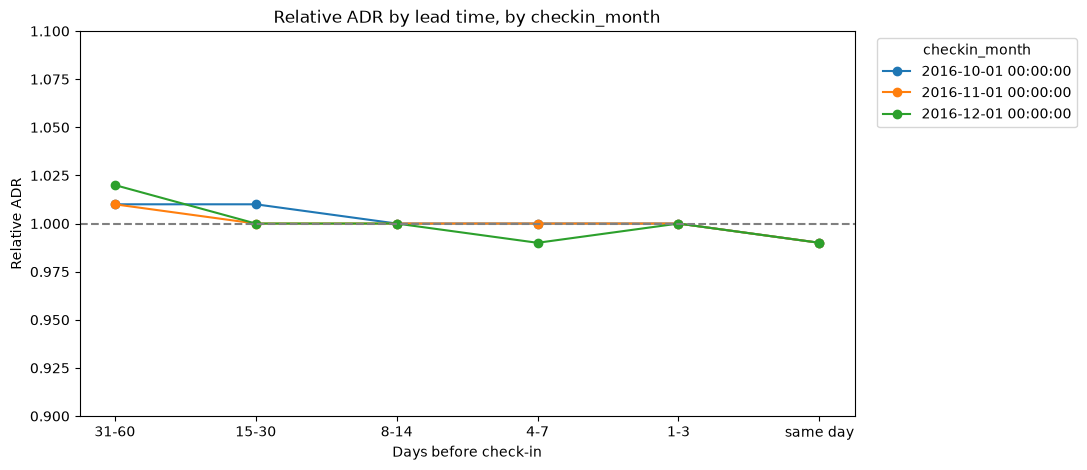

count  median
checkin_month lt_band                
2016-10-01    same day   1778    0.99
              1-3        3748    1.00
              4-7        2297    1.00
              8-14       2199    1.00
              15-30      2930    1.01
              31-60      2280    1.01
2016-11-01    same day   1581    0.99
              1-3        3201    1.00
              4-7        1995    1.00
              8-14       2044    1.00
              15-30      2821    1.00
              31-60      2472    1.01
2016-12-01    same day   1736    0.99
              1-3        3270    1.00
              4-7        2134    0.99
              8-14       2571    1.00
              15-30      3455    1.00
              31-60      3185    1.02

In [38]:
price_curve(new_df, "checkin_month")

- All three check-in months show the same nearly flat pattern: 1.01–1.02 far ahead → 0.99 same day (1–3%). Seasonality doesn't change the curve.

#### City

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 30


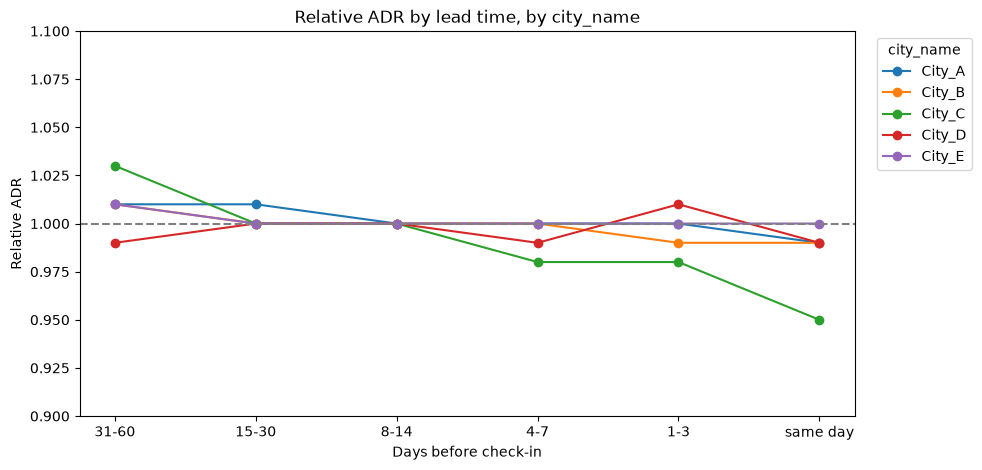

count  median
city_name lt_band                
City_A    same day   2755    0.99
          1-3        5274    1.00
          4-7        3031    1.00
          8-14       3202    1.00
          15-30      4091    1.01
          31-60      3287    1.01
City_B    same day    494    0.99
          1-3         917    0.99
          4-7         407    1.00
          8-14        423    1.00
          15-30       630    1.00
          31-60       636    1.01
City_C    same day    279    0.95
          1-3         844    0.98
          4-7         771    0.98
          8-14        972    1.00
          15-30      1662    1.00
          31-60      1733    1.03
City_D    same day    838    0.99
          1-3        1950    1.01
          4-7        1575    0.99
          8-14       1634    1.00
          15-30      2112    1.00
          31-60      1745    0.99
City_E    same day    729    1.00
          1-3        1234    1.00
          4-7         642    1.00
          8-14        583    1.00
          15-30       711    1.00
          31-60       536    1.01

In [39]:
price_curve(new_df, "city_name")

In [40]:
# share of bookings made within 3 days of check-in, by city
(new_df["lead_time"] <= 3).groupby(new_df["city_name"]).mean().round(2)

city_name
City_A    0.38
City_B    0.42
City_C    0.18
City_D    0.28
City_E    0.44
Name: lead_time, dtype: float64

- City C is the only city with a clear pattern: relative ADR falls from 1.03 (31–60 days) to 0.95 (same day), about 8% cheaper for last-minute bookings, with solid counts (279+ per band).
- City A, B, D and E are nearly flat (within 1–2%).
- City E has the highest share of last-minute bookings (44% within 3 days), but its prices stay at the usual level. City C has the lowest share (18%) and the biggest last-minute drop.
- No city shows prices rising as check-in approaches.

#### Accommodation type

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 39


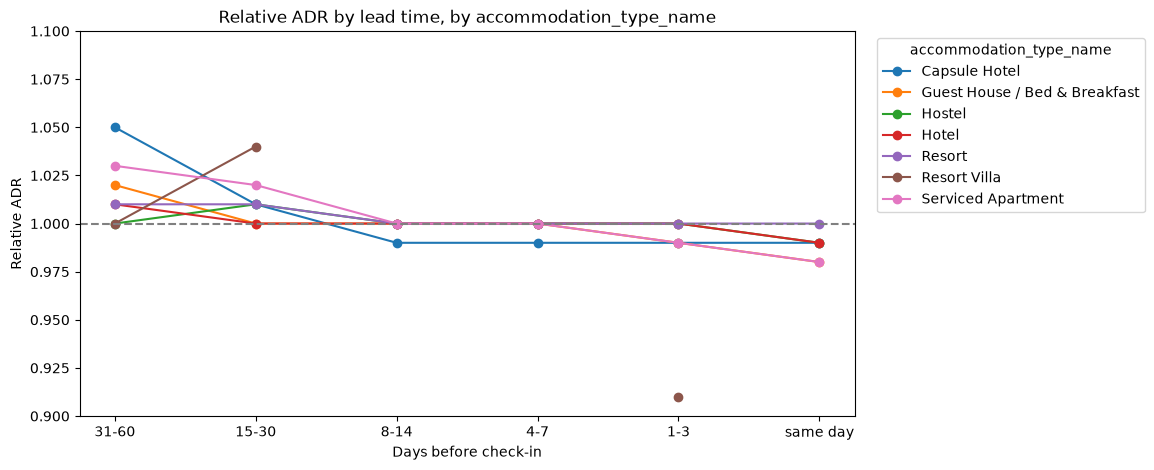

count  median
accommodation_type_name       lt_band                
Capsule Hotel                 same day     53    0.99
                              1-3         127    0.99
                              4-7         122    0.99
                              8-14        127    0.99
                              15-30       198    1.01
                              31-60       161    1.05
Guest House / Bed & Breakfast same day    243    0.98
                              1-3         487    0.99
                              4-7         291    1.00
                              8-14        289    1.00
                              15-30       425    1.00
                              31-60       352    1.02
Hostel                        same day    241    0.99
                              1-3         498    1.00
                              4-7         354    1.00
                              8-14        350    1.00
                              15-30       576    1.01
                              31-60       504    1.00
Hotel                         same day   3685    0.99
                              1-3        7576    1.00
                              4-7        4843    1.00
                              8-14       5274    1.00
                              15-30      6951    1.00
                              31-60      6031    1.01
Resort                        same day    419    1.00
                              1-3         776    1.00
                              4-7         426    1.00
                              8-14        368    1.00
                              15-30       532    1.01
                              31-60       461    1.01
Resort Villa                  1-3          40    0.91
                              15-30        38    1.04
                              31-60        44    1.00
Serviced Apartment            same day    423    0.98
                              1-3         671    0.99
                              4-7         346    1.00
                              8-14        356    1.00
                              15-30       434    1.02
                              31-60       328    1.03

In [41]:
price_curve(new_df, "accommodation_type_name")

- Types with enough data drift slightly down near check-in. Capsule Hotel (1.05 → 0.99, ~6%), Serviced Apartment (1.03 → 0.98, ~5%) and Guest House (1.02 → 0.98, ~4%) dip the most; Hotel, Hostel and Resort are nearly flat (1–2%).
- Capsule Hotel is entirely in City C, so its dip may be a City C effect (checked below).
- Resort Villa, Apartment, Ryokan and the other small types have too few bookings per lead time band (under 30) to assess.
- No type shows prices rising near check-in.

#### City C by accommodation type - what drives City C's drop?

Bookings kept: 6,261 of 6,797 (92%)
Points shown (count >= 30): 25


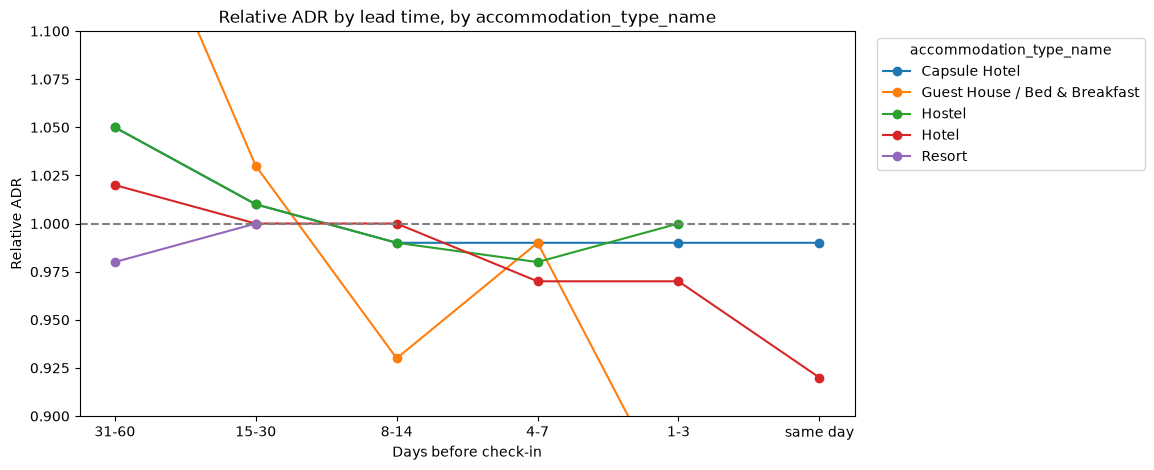

count  median
accommodation_type_name       lt_band                
Capsule Hotel                 same day     53    0.99
                              1-3         127    0.99
                              4-7         122    0.99
                              8-14        127    0.99
                              15-30       198    1.01
                              31-60       161    1.05
Guest House / Bed & Breakfast same day     30    0.88
                              1-3          76    0.85
                              4-7          53    0.99
                              8-14         48    0.93
                              15-30        77    1.03
                              31-60        85    1.20
Hostel                        1-3          71    1.00
                              4-7          53    0.98
                              8-14         62    0.99
                              15-30        84    1.01
                              31-60        63    1.05
Hotel                         same day    169    0.92
                              1-3         560    0.97
                              4-7         530    0.97
                              8-14        716    1.00
                              15-30      1222    1.00
                              31-60      1337    1.02
Resort                        15-30        53    1.00
                              31-60        51    0.98

In [42]:
price_curve(new_df[new_df["city_name"] == "City_C"], "accommodation_type_name")

- **The City C drop is driven by regular hotels.** City C hotels fall from 1.02 (31–60 days) to 0.92 (same day), about 10%, with solid counts (169–1,337 per band). Hotels are about 70% of City C's bookings, so they carry the city's pattern.
- **Guest House: big swings, but thin data.** It moves from 1.20 to 0.85–0.88 with only 30–85 bookings per band, and it zigzags (0.93, 0.99, 0.85). The direction matches the hotels, but the numbers aren't reliable. (The 1.20 point is above the chart's y-axis limit.)
- **Capsule Hotel and Hostel** only have a small premium far ahead (1.05), then stay flat at 0.98–1.00. They don't drop further at the last minute.

#### Sanity check - City A (biggest city) by accommodation type

Bookings kept: 21,640 of 22,365 (97%)
Points shown (count >= 30): 24


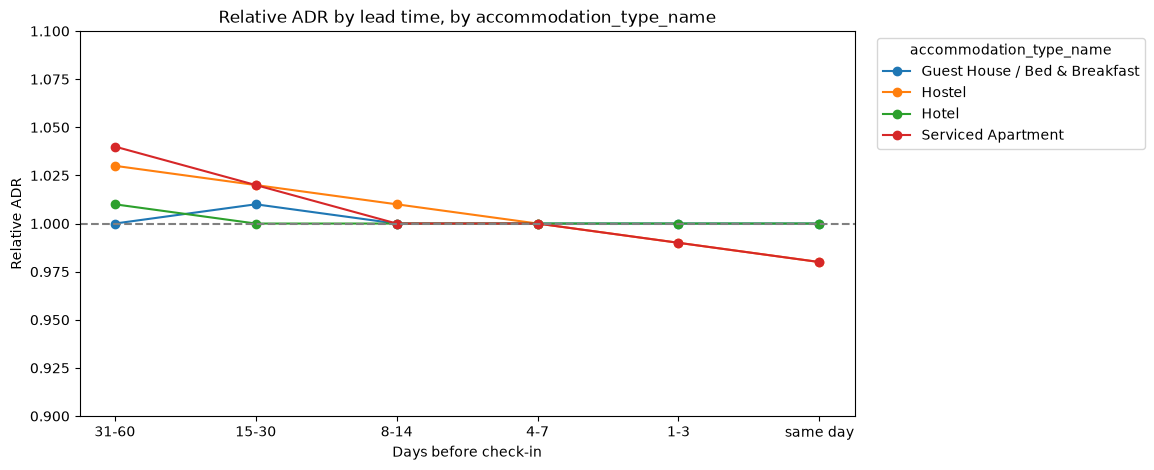

count  median
accommodation_type_name       lt_band                
Guest House / Bed & Breakfast same day     59    1.00
                              1-3          92    1.00
                              4-7          67    1.00
                              8-14         61    1.00
                              15-30        73    1.01
                              31-60        58    1.00
Hostel                        same day    128    0.98
                              1-3         213    0.99
                              4-7         121    1.00
                              8-14        124    1.01
                              15-30       174    1.02
                              31-60       108    1.03
Hotel                         same day   2230    1.00
                              1-3        4394    1.00
                              4-7        2534    1.00
                              8-14       2691    1.00
                              15-30      3464    1.00
                              31-60      2865    1.01
Serviced Apartment            same day    335    0.98
                              1-3         558    0.99
                              4-7         305    1.00
                              8-14        323    1.00
                              15-30       373    1.02
                              31-60       253    1.04

In [43]:
price_curve(new_df[new_df["city_name"] == "City_A"], "accommodation_type_name")

- City A hotels are flat (1.01 → 1.00). Serviced Apartment (1.04 → 0.98) and Hostel (1.03 → 0.98) drift down about 5%; Guest House is flat.
- So the ~10% last-minute drop for hotels is specific to City C, not a general hotel pattern.

#### Star rating

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 54


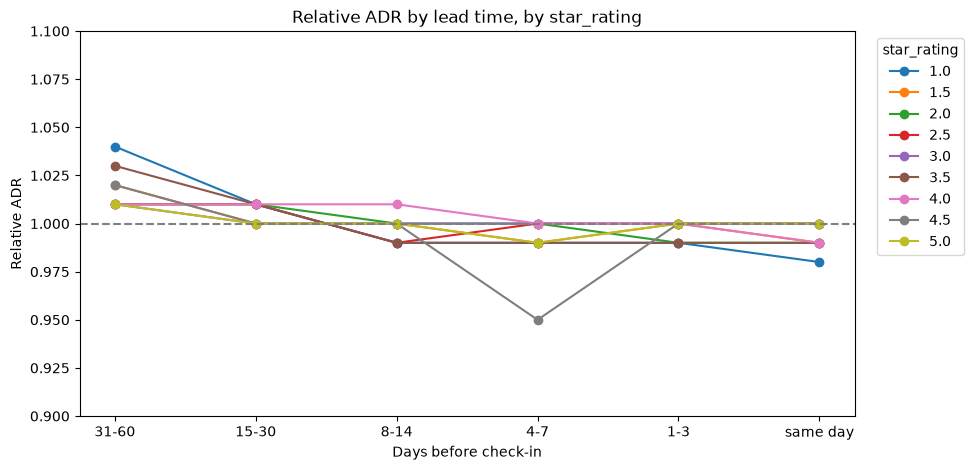

count  median
star_rating lt_band                
1.0         same day    259    0.98
            1-3         579    0.99
            4-7         397    0.99
            8-14        380    0.99
            15-30       621    1.01
            31-60       528    1.04
1.5         same day     30    0.99
            1-3          78    1.00
            4-7          62    0.99
            8-14         67    1.00
            15-30        81    1.00
            31-60        63    1.02
2.0         same day    245    0.99
            1-3         489    0.99
            4-7         229    1.00
            8-14        250    1.00
            15-30       302    1.01
            31-60       290    1.01
2.5         same day    211    1.00
            1-3         364    1.00
            4-7         229    1.00
            8-14        232    0.99
            15-30       345    1.01
            31-60       367    1.01
3.0         same day   1370    1.00
            1-3        2768    1.00
            4-7        1799    1.00
            8-14       2012    1.00
            15-30      2938    1.00
            31-60      2729    1.01
3.5         same day    560    0.99
            1-3        1311    0.99
            4-7         875    0.99
            8-14       1013    0.99
            15-30      1322    1.01
            31-60      1142    1.03
4.0         same day   1832    0.99
            1-3        3478    1.00
            4-7        2100    1.00
            8-14       2144    1.01
            15-30      2492    1.01
            31-60      1994    1.01
4.5         same day     92    1.00
            1-3         207    1.00
            4-7         153    0.95
            8-14        175    1.00
            15-30       250    1.00
            31-60       217    1.02
5.0         same day    482    1.00
            1-3         926    1.00
            4-7         569    0.99
            8-14        531    1.00
            15-30       849    1.00
            31-60       601    1.01

In [44]:
price_curve(new_df, "star_rating")

- 3.0, 3.5 and 4.0 stars hold most of the bookings, and all three are close to flat (1–3%).
- 1-star dips the most: 1.04 → 0.98, about 6%. 5-star is the flattest: 1.01 → 1.00.
- The single 4.5-star dip at 4–7 days (0.95) is isolated; checked below.

#### Who is behind the 4.5-star dip at 4–7 days?

In [45]:
d = new_df[(new_df["star_rating"] == 4.5) & (new_df["lead_time"].between(4, 7))]
print(d["hotel_id"].value_counts().head())

hotel_id
373272    69
21360     58
217846    12
608654     7
133050     7
Name: count, dtype: int64


- The 4.5-star dip at 4–7 days is driven by two properties that make up most of that band, so it isn't a general 4.5-star pattern.

#### Chain status

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 12


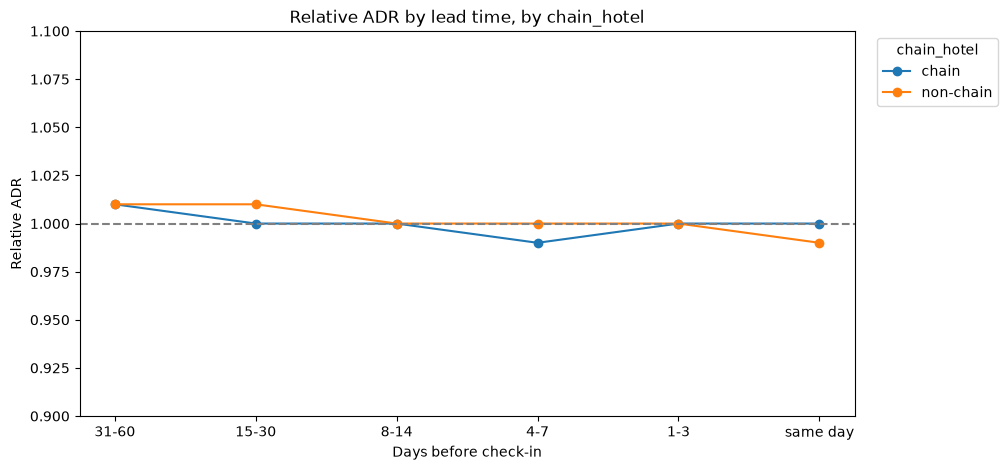

count  median
chain_hotel lt_band                
chain       same day   1422    1.00
            1-3        2743    1.00
            4-7        1800    0.99
            8-14       1956    1.00
            15-30      2655    1.00
            31-60      2237    1.01
non-chain   same day   3673    0.99
            1-3        7476    1.00
            4-7        4626    1.00
            8-14       4858    1.00
            15-30      6551    1.01
            31-60      5700    1.01

In [46]:
price_curve(new_df, "chain_hotel")

- Chain and non-chain are both flat (1.01 → 1.00 and 1.01 → 0.99), so chain status doesn't change how price moves with lead time.
- Chain properties charge more (median $161 vs $92, section 3), but that's a difference in price level, not in how price changes as check-in approaches.

#### Booking day - weekday vs weekend

Bookings kept: 45,697 of 49,061 (93%)
Points shown (count >= 30): 12


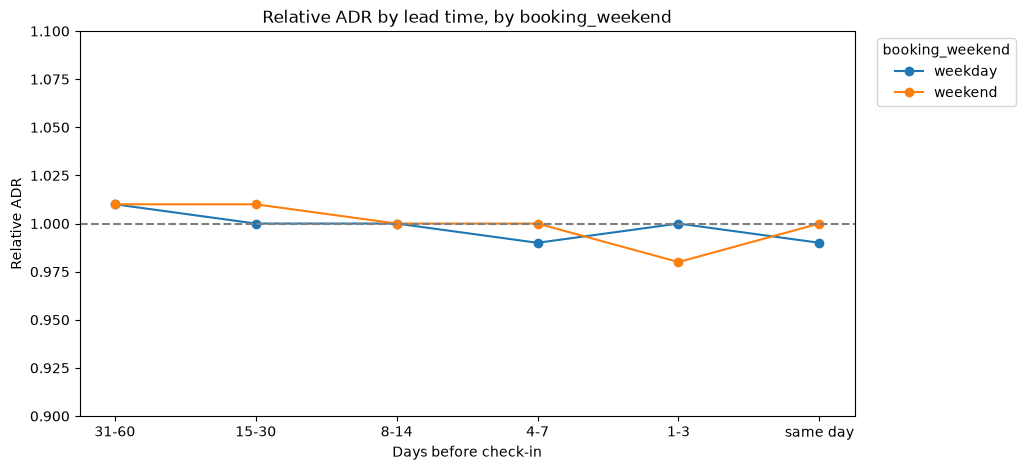

count  median
booking_weekend lt_band                
weekday         same day   3479    0.99
                1-3        7929    1.00
                4-7        4880    0.99
                8-14       5282    1.00
                15-30      6987    1.00
                31-60      5864    1.01
weekend         same day   1616    1.00
                1-3        2290    0.98
                4-7        1546    1.00
                8-14       1532    1.00
                15-30      2219    1.01
                31-60      2073    1.01

In [47]:
price_curve(new_df, "booking_weekend")

In [48]:
# raw ADR by booking day
new_df.groupby(["booking_weekend", "lt_band"], observed=True)["ADR_USD"].agg(["count", "median"]).round(2)

count  median
booking_weekend lt_band                
weekday         same day   3817   85.48
                1-3        8618  100.00
                4-7        5160  114.53
                8-14       5644  120.33
                15-30      7441  131.06
                31-60      6261  138.40
weekend         same day   1786   89.51
                1-3        2440   94.10
                4-7        1658  105.24
                8-14       1637  117.20
                15-30      2369  118.76
                31-60      2230  135.75

In [49]:
# lead time mix by booking day
new_df.groupby("booking_weekend")["lt_band"].value_counts(normalize=True).sort_index().round(3)

booking_weekend  lt_band 
weekday          same day    0.103
                 1-3         0.233
                 4-7         0.140
                 8-14        0.153
                 15-30       0.201
                 31-60       0.169
weekend          same day    0.147
                 1-3         0.201
                 4-7         0.137
                 8-14        0.135
                 15-30       0.195
                 31-60       0.184
Name: proportion, dtype: float64

- Price curve: booking on a weekday or a weekend makes no difference; both are flat (within ~2%).
- Raw ADR falls the same way for both (~$136–138 at 31–60 days → $85–90 same day). That's the mix effect (cheaper properties get booked later), not a price change; see key takeaway 2.
- About a third of bookings are made within 3 days of check-in either way. Weekend shoppers more often book for the same night (15% vs 10%), while weekday shoppers more often book 1–3 days ahead (23% vs 20%).

---

# 5. Key takeaways

### 1. About 1 in 3 bookings is made within 3 days of check-in

lt_band
same day     11.4
1-3          34.0
4-7          47.9
8-14         62.7
15-30        82.7
31-60       100.0
Name: ADR_USD, dtype: float64


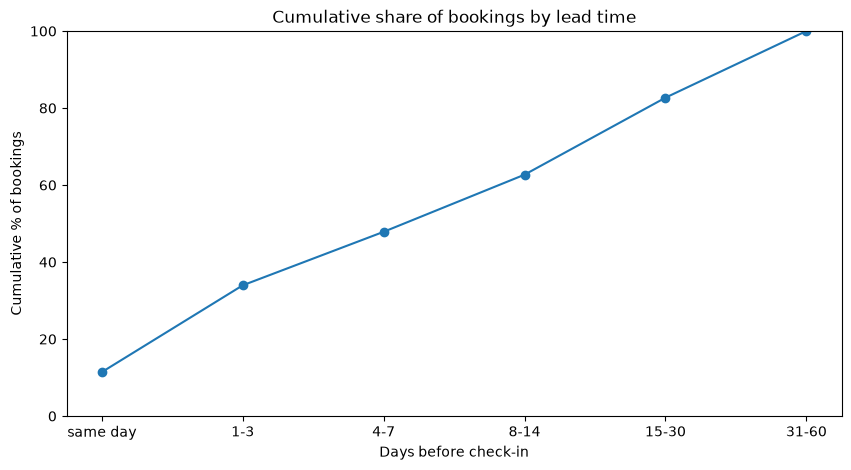

In [50]:
stat = new_df.groupby("lt_band", observed=True)["ADR_USD"].count()
cum_pct = stat.cumsum() / stat.sum() * 100
print(cum_pct.round(1))

ax = cum_pct.plot(marker="o", figsize=(10, 5), title="Cumulative share of bookings by lead time")
ax.set_ylabel("Cumulative % of bookings")
ax.set_xlabel("Days before check-in")
ax.set_ylim(0, 100)
plt.show()

- 11% of bookings are same-day and 34% are made within 3 days of check-in. About half (48%) are made within a week.
- Last-minute booking is a big share of the business, and it's exactly the moment urgency messages target.

### 2. Raw prices look like they fall near check-in

lt_band
same day     86.56
1-3          98.82
4-7         112.48
8-14        119.96
15-30       127.64
31-60       137.66
Name: ADR_USD, dtype: float64
Same day vs 31-60 days out: -37.1%


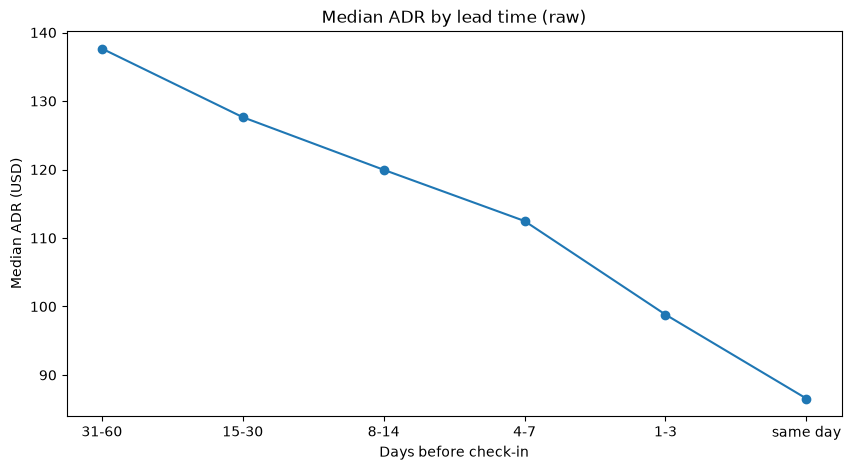

In [51]:
raw_adr = new_df.groupby("lt_band", observed=True)["ADR_USD"].median()
print(raw_adr)
diff_pct = (raw_adr.loc["same day"] / raw_adr.loc["31-60"] - 1) * 100
print(f"Same day vs 31-60 days out: {diff_pct:.1f}%")

raw_adr.iloc[::-1].plot(marker="o", figsize=(10, 5), title="Median ADR by lead time (raw)")
plt.ylabel("Median ADR (USD)")
plt.xlabel("Days before check-in")
plt.show()

- Median ADR is $138 for bookings made 31–60 days ahead vs $87 for same-day bookings, about 37% lower.
- This looks like prices drop near check-in, but it compares *different* properties: expensive properties (City C/D, resorts, 4–5 star) are booked further ahead and cheaper ones are booked late (section 3, Part 4). It's a mix effect.

### 3. But the same property's price is nearly flat across the booking window

lt_band
same day    0.993
1-3         0.997
4-7         0.996
8-14        1.000
15-30       1.004
31-60       1.012
Name: rel_adr, dtype: float64


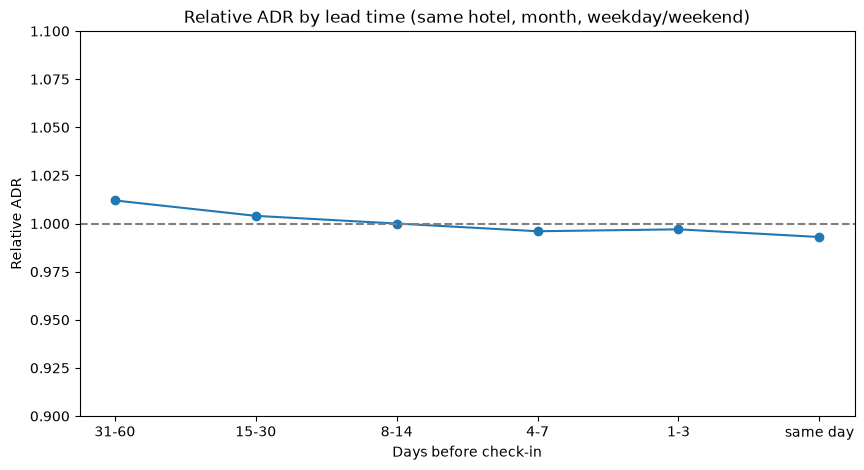

In [52]:
valid = new_df[new_df["baseline_size"] >= 5]   # drop baseline groups too small for a stable median
rel = valid.groupby("lt_band", observed=True)["rel_adr"].median()
print(rel)

rel.iloc[::-1].plot(marker="o", figsize=(10, 5), title="Relative ADR by lead time (same hotel, month, weekday/weekend)")
plt.ylim(0.90, 1.10)
plt.axhline(1, color="gray", linestyle="--")
plt.ylabel("Relative ADR")
plt.xlabel("Days before check-in")
plt.show()

- Compared with the same hotel's usual price (same check-in month, same weekday/weekend night), relative ADR goes from 1.01 (31–60 days) to 0.99 (same day): about 2% lower, nearly flat.
- So the 37% raw drop is almost entirely a mix effect, not properties changing their prices.
- This holds across baselines, minimum group sizes (5–20), check-in months, cities (except City C), accommodation types, star ratings, chain status and booking day.

### 4. One exception: City C
- City C prices fall about 8% from far ahead to same day (1.03 → 0.95), driven by its regular hotels (1.02 → 0.92, ~10%).
- City C also has the fewest last-minute bookings (18% within 3 days vs 28–44% elsewhere). That fits properties lowering prices to fill rooms that weren't booked early, but this data can't confirm why.
- No segment shows prices **rising** near check-in.

### 5. What this means for urgency messaging
- *"Prices are rising, book now"* isn't supported by this data for any segment, so it would be misleading.
- Other kinds of urgency may still be honest, such as availability ("only 2 rooms left") or popularity ("booked 5 times today"). These don't depend on price, but testing them needs inventory or search data.
- In City C, "last-minute deal" framing fits the data better than price urgency.

### 6. Limitations
- **Only completed bookings are observed.** Properties that sold out early, or got too expensive and weren't booked, don't appear in the last-minute bands. So late prices may look lower than what guests actually saw when searching. Search or rate-snapshot data would close that gap.
- Check-ins cover Oct–Dec 2016 only, lead time is capped at 60 days, and stays are 1–3 nights.
- 1,024 exact duplicate rows (2%) are kept because there's no booking ID to tell them apart from real repeat bookings.